# Carleman Linearization

**Turning a nonlinear equation into a linear one**

Nonlinearity is what makes fluid dynamics hard (see the subject notebook): the convective term
$(\mathbf{u}\cdot\nabla)\mathbf{u}$ couples the field to itself. **Carleman linearization** is a
classical technique that converts a nonlinear dynamical system into an *infinite* linear system by
tracking all the monomials of the state. Truncating that system gives a finite **linear** system
whose solution approximates the nonlinear one.

This matters here because *linear* systems are the ones quantum algorithms know how to attack:
once a problem is linear, its matrix can be block-encoded (see the block-encoding notebook) and
processed with a quantum linear-solver or quantum-signal-processing primitive.

This notebook:

1. explains the idea (monomials form a linear chain);
2. derives it for the simplest quadratic ODE $\dot x = \lambda x + \mu x^2$;
3. verifies that the truncated linear system converges to the exact nonlinear solution;
4. connects it to the Burgers / Navier–Stokes nonlinearity of the hackathon.

Requires `numpy`, `matplotlib` and `scipy`.

## Environment

```bash
pip install numpy matplotlib scipy
```

## 1. The idea

Take a nonlinear system $\dot{\mathbf{x}} = f(\mathbf{x})$. If $f$ is (at least) polynomial, then
the derivative of any monomial of the state is a sum of *higher-degree* monomials. For a
**quadratic** nonlinearity (the case relevant to fluids), the derivative of a degree-$k$ monomial
depends only on monomials of degree $k$ and $k+1$:

$$\frac{d}{dt}\big(x^k\big) = k\,x^{k-1}\,\dot x = k\,x^{k-1} f(x)
\;\;\longrightarrow\;\; \text{monomials of degree } k \text{ and } k+1 .$$

So the monomials $x, x^2, x^3, \dots$ form an **infinite linear chain**: each one's derivative
points to the next one up. Written as a vector $z = (x, x^2, x^3, \dots)^\top$,

$$\dot z = M z$$

where $M$ is an infinite (upper-triangular) matrix. This is **linear** — the nonlinearity has been
pushed into the *size* of the system. Truncate at degree $N$ to get a finite linear system
$\dot z = M z$, $z \in \mathbb{R}^N$, which we can solve exactly.

## 2. A worked derivation

Consider the simplest nonlinear ODE with a quadratic term — a logistic / Bernoulli equation:

$$\dot x = \lambda x + \mu x^2, \qquad x(0) = x_0 .$$

Let $z_k = x^k$. Then

$$\dot z_k = k\,x^{k-1}\dot x = k\,x^{k-1}\big(\lambda x + \mu x^2\big)
= k\lambda\,z_k + k\mu\,z_{k+1}.$$

So the $k$-th monomial couples to itself and to the next one up. Truncating at order $N$, the
matrix $M$ is upper-bidiagonal:

$$M = \begin{bmatrix}
\lambda & \mu & & & \\
 & 2\lambda & 2\mu & & \\
 & & 3\lambda & 3\mu & \\
 & & & \ddots & \ddots \\
 & & & & N\lambda
\end{bmatrix},$$

and $z(0) = (x_0, x_0^2, \dots, x_0^N)^\top$. The first component of the solution
$z(t) = e^{Mt} z(0)$ approximates the true $x(t)$.

In [1]:
import numpy as np
import matplotlib.pyplot as plt
from scipy.linalg import expm

# ---------------------------------------------------------------------------
# Carleman linearization of  x' = lam x + mu x^2
# ---------------------------------------------------------------------------
def carleman_matrix(lam, mu, N):
    """Upper-bidiagonal Carleman matrix for the monomials x, x^2, ..., x^N."""
    M = np.zeros((N, N))
    for k in range(1, N + 1):
        M[k - 1, k - 1] = k * lam          # d(x^k)/dt gets k*lam*x^k
        if k < N:
            M[k - 1, k] = k * mu           # ... and k*mu*x^(k+1)
    return M

def carleman_solution(lam, mu, x0, N, t):
    """z(t) = exp(M t) z(0); the first entry approximates x(t)."""
    M = carleman_matrix(lam, mu, N)
    z0 = np.array([x0**k for k in range(1, N + 1)])
    return expm(M * t) @ z0

def exact_solution(lam, mu, x0, t):
    """Exact solution of x' = lam x + mu x^2  (via the substitution v = 1/x)."""
    v0 = 1.0 / x0
    v = (v0 + mu / lam) * np.exp(-lam * t) - mu / lam
    return 1.0 / v

lam, mu, x0 = 0.3, 0.4, 0.2
print("setup ok")

setup ok


## 3. Does the truncation converge?

The higher the truncation order $N$, the more of the monomial chain we keep, so the better the
approximation. Let us compare $x_{\text{car}}(T)$ to the exact value as $N$ grows.

In [2]:
T = 3.0
x_exact = exact_solution(lam, mu, x0, T)
print(f"exact x({T}) = {x_exact:.6f}")
print(f"{'N':>3} {'x_car':>12} {'rel. error':>12}")
for N in [3, 5, 8, 12, 16]:
    x_car = carleman_solution(lam, mu, x0, N, T)[0]
    err = abs(x_car - x_exact) / abs(x_exact)
    print(f"{N:>3} {x_car:>12.6f} {err:>12.2e}")

exact x(3.0) = 0.805407
  N        x_car   rel. error
  3     0.757915     5.90e-02
  5     0.798212     8.93e-03
  8     0.804983     5.27e-04
 12     0.805398     1.21e-05
 16     0.805407     2.77e-07


## 4. The trajectory over time

Here we fix one truncation order and compare the whole trajectory $x(t)$ to the exact solution. We
also see the error grow as the nonlinearity takes effect.

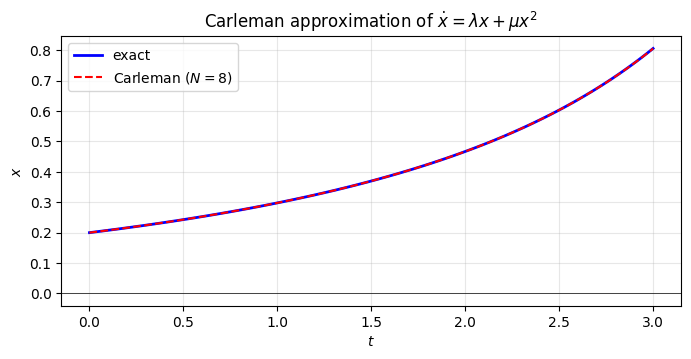

In [3]:
N = 8
tt = np.linspace(0, T, 100)

x_car = [carleman_solution(lam, mu, x0, N, t)[0] for t in tt]
x_ref = [exact_solution(lam, mu, x0, t) for t in tt]

plt.figure(figsize=(8, 3.5))
plt.plot(tt, x_ref, 'b-', lw=2, label='exact')
plt.plot(tt, x_car, 'r--', lw=1.5, label=f'Carleman ($N={N}$)')
plt.axhline(0, color='k', lw=0.5)
plt.legend(); plt.title(r'Carleman approximation of $\dot x = \lambda x + \mu x^2$')
plt.xlabel('$t$'); plt.ylabel('$x$'); plt.grid(alpha=0.3)
plt.show()

## References

- T. Carleman, *Application de la théorie des équations intégrales linéaires aux systèmes
  d'équations différentielles non linéaires*, Acta Math. 59 (1932) 63–87.
- J.-P. Liu, H. Ø. Kolden, H. K. Krovi, N. F. Loureiro, K. Trivisa, A. M. Childs,
  *Efficient quantum algorithm for dissipative nonlinear differential equations*,
  PNAS 118 (2021) e2026805118.
- S. Kowalski, *Kowalski's Carleman linearization* and related reviews.